# Problema 7 — Clasificación temporal y política de alertas

**Aprendizaje Automático · Taller 1 · 2026-2S**

Este notebook sigue los incisos (a)–(e) del enunciado. Mantiene el orden temporal, usa `min_retraso` solo para construir la etiqueta y excluye `fecha_prediccion` de los predictores. El módulo `FuncionesReutilizables.py` es la implementación común del modelo logístico no ponderado.

> **Antes de ejecutar:** coloca `FuncionesReutilizables.py` y el notebook de clase que contiene `generar_vuelos` en la misma carpeta. El cargador busca automáticamente la función en los notebooks vecinos. Si el notebook de clase no está disponible, el código se detiene con un mensaje claro en vez de inventar o cambiar el generador.

In [ ]:
%pip install scikit-learn

## 0. Preparación e imports

In [ ]:
from pathlib import Path
import json, warnings, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    average_precision_score, roc_auc_score, log_loss, brier_score_loss,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, precision_recall_curve, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

SEED = 2026
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)

### Generación local de vuelos sintéticos

La función `generar_vuelos()` se define directamente en este notebook para que no dependa de otros notebooks de la carpeta. Se conserva el mecanismo del generador y se usa la semilla exigida por el taller (`seed=2026`). La etiqueta observada se construye a partir de `min_retraso`; las probabilidades internas del generador no se utilizan.

In [ ]:
def generar_vuelos(n=9600, seed=SEED):
    rng = np.random.default_rng(seed)
    fecha = pd.date_range('2024-01-01', periods=n, freq='h')
    hora = ((fecha + pd.Timedelta(hours=2)).hour).to_numpy()
    progreso = np.linspace(0, 1, n)
    aerolinea = rng.choice(['Aero_A', 'Aero_B', 'Aero_C'], n, p=[0.50, 0.30, 0.20])
    origen = rng.choice(['BOG', 'MDE', 'CLO', 'CTG'], n)
    distancia = rng.uniform(200, 1800, n)
    lluvia = rng.gamma(shape=1.2, scale=2.0, size=n)
    viento = np.clip(rng.normal(15, 6, n), 0, 45)
    ocupacion = np.clip(rng.normal(77, 12, n), 25, 100)
    trafico = np.clip(rng.normal(45 + 10 * progreso, 13, n), 5, 100)

    # Probabilidad del simulador: combina factores conocidos antes de la salida.
    logit = (
        -5.3 + 1.1 * (trafico - 45) / 13
        + 0.8 * (lluvia - 2.4) / 2.2 + 0.7 * (viento - 15) / 6
        + 0.35 * (ocupacion - 77) / 12 + 0.55 * (hora >= 17)
        + 0.40 * (origen == 'BOG') + 0.45 * (aerolinea == 'Aero_C')
    )
    probabilidad_generadora = 1 / (1 + np.exp(-logit))

    # La etiqueta se sortea: vuelos similares pueden tener resultados distintos.
    positivo = rng.binomial(1, probabilidad_generadora)
    retraso = np.where(
        positivo == 1,
        rng.integers(15, 181, n),
        rng.integers(-10, 15, n)
    )

    datos = pd.DataFrame({
        'fecha_prediccion': fecha,
        'hora_salida': hora,
        'distancia_km': distancia,
        'lluvia_pronosticada_mm': lluvia,
        'viento_pronosticado_kmh': viento,
        'ocupacion_programada_pct': ocupacion,
        'trafico_programado': trafico,
        'aerolinea': aerolinea,
        'origen': origen,
        'min_retraso': retraso,
    })

    # Los faltantes afectan a predictores, nunca a la etiqueta observada.
    for columna in [
        'lluvia_pronosticada_mm',
        'viento_pronosticado_kmh',
        'ocupacion_programada_pct',
        'aerolinea'
    ]:
        datos.loc[rng.random(n) < 0.06, columna] = np.nan

    return datos


# Ejecutar el generador con los parámetros exigidos.
datos = generar_vuelos(n=9600, seed=2026)
datos = datos.copy()

# Definición de la variable objetivo.
datos["Y"] = (datos["min_retraso"] >= 15).astype(int)
datos["id_fila"] = np.arange(len(datos), dtype=int)

assert len(datos) == 9600
assert set(datos["Y"].unique()).issubset({0, 1})

# Comprobación de la base generada. min_retraso se conserva para auditoría,
# pero NO se usa como predictor.
display(datos.head())

,fecha_prediccion,hora_salida,distancia_km,lluvia_pronosticada_mm,viento_pronosticado_kmh,ocupacion_programada_pct,trafico_programado,aerolinea,origen,min_retraso,Y,id_fila
0,2024-01-01 00:00:00,2,862.834833,2.219217,5.283332,69.709151,39.181675,Aero_A,MDE,11,0,0
1,2024-01-01 01:00:00,3,326.896114,4.169936,17.050673,62.324764,35.405478,Aero_B,CLO,0,0,1
2,2024-01-01 02:00:00,4,418.357099,0.726960,9.758701,67.730544,22.517978,Aero_A,MDE,1,0,2
3,2024-01-01 03:00:00,5,1415.548734,1.052647,NaN,72.911455,37.927190,Aero_A,CTG,4,0,3
4,2024-01-01 04:00:00,6,799.143007,0.676545,10.779927,68.071442,44.468961,Aero_A,BOG,9,0,4


## 1. Diccionario de variables y auditoría temporal (7a)

La predicción se formula dos horas antes de la salida. Se admiten como entradas las variables programadas o pronosticadas disponibles en ese momento. `fecha_prediccion` sirve exclusivamente para ordenar y definir particiones; `min_retraso` se usa exclusivamente para obtener la etiqueta.

In [ ]:
diccionario = pd.DataFrame([
    ["fecha_prediccion", "Marca temporal", "Sí, solo ordenar/partir", "No"],
    ["hora_salida", "Hora de salida (con ajuste horario del generador)", "Sí", "Sí"],
    ["distancia_km", "Distancia del vuelo en km", "Sí", "Sí"],
    ["lluvia_pronosticada_mm", "Lluvia pronosticada en mm", "Sí; puede faltar", "Sí"],
    ["viento_pronosticado_kmh", "Viento pronosticado en km/h", "Sí; puede faltar", "Sí"],
    ["ocupacion_programada_pct", "Ocupación programada (%)", "Sí; puede faltar", "Sí"],
    ["trafico_programado", "Indicador de tráfico programado", "Sí", "Sí"],
    ["aerolinea", "Aerolínea programada", "Sí; puede faltar", "Sí"],
    ["origen", "Aeropuerto de origen", "Sí", "Sí"],
    ["min_retraso", "Retraso observado en minutos", "Solo construir Y", "No"],
    ["Y", "1 si min_retraso >= 15; 0 en otro caso", "Objetivo observado", "No"]
], columns=["variable", "significado", "disponibilidad/uso", "predictor"])
display(diccionario)

# Orden cronológico estable y comprobación de identidad
datos = datos.sort_values(["fecha_prediccion", "id_fila"], kind="stable").reset_index(drop=True)
datos["id_temporal"] = np.arange(len(datos))
print("Dimensiones:", datos.shape)
print("Fechas:", datos.fecha_prediccion.min(), "→", datos.fecha_prediccion.max())
print("Fechas ordenadas:", datos.fecha_prediccion.is_monotonic_increasing)
display(datos[["fecha_prediccion", "id_fila", "Y"]].head(3))
display(datos[["fecha_prediccion", "id_fila", "Y"]].tail(3))

,variable,significado,disponibilidad/uso,predictor
0,fecha_prediccion,Marca temporal,"Sí, solo ordenar/partir",No
1,hora_salida,Hora de salida (con ajuste horario del generador),Sí,Sí
2,distancia_km,Distancia del vuelo en km,Sí,Sí
3,lluvia_pronosticada_mm,Lluvia pronosticada en mm,Sí; puede faltar,Sí
4,viento_pronosticado_kmh,Viento pronosticado en km/h,Sí; puede faltar,Sí
5,ocupacion_programada_pct,Ocupación programada (%),Sí; puede faltar,Sí
6,trafico_programado,Indicador de tráfico programado,Sí,Sí
7,aerolinea,Aerolínea programada,Sí; puede faltar,Sí
8,origen,Aeropuerto de origen,Sí,Sí
9,min_retraso,Retraso observado en minutos,Solo construir Y,No


Dimensiones: (9600, 13)
Fechas: 2024-01-01 00:00:00 → 2025-02-03 23:00:00
Fechas ordenadas: True


,fecha_prediccion,id_fila,Y
0,2024-01-01 00:00:00,0,0
1,2024-01-01 01:00:00,1,0
2,2024-01-01 02:00:00,2,0


,fecha_prediccion,id_fila,Y
9597,2025-02-03 21:00:00,9597,0
9598,2025-02-03 22:00:00,9598,0
9599,2025-02-03 23:00:00,9599,0


In [ ]:
# Auditoría de tipos y faltantes de la base cruda (descriptiva, sin imputar)
auditoria = pd.DataFrame({
    "dtype": datos.dtypes.astype(str),
    "faltantes": datos.isna().sum(),
    "porcentaje_faltante": (100 * datos.isna().mean()).round(2),
    "n_unicos": datos.nunique(dropna=True)
})
display(auditoria)

# Distribuciones solo sobre el conjunto de entrenamiento, después de definir los cortes

,dtype,faltantes,porcentaje_faltante,n_unicos
fecha_prediccion,datetime64[ns],0,0.00,9600
hora_salida,int32,0,0.00,24
distancia_km,float64,0,0.00,9600
lluvia_pronosticada_mm,float64,587,6.11,9013
viento_pronosticado_kmh,float64,619,6.45,8927
ocupacion_programada_pct,float64,604,6.29,8747
trafico_programado,float64,0,0.00,9596
aerolinea,object,582,6.06,3
origen,object,0,0.00,4
min_retraso,int64,0,0.00,151


## 2. Cortes cronológicos con gap de 24 filas

Se aplican cortes nominales en 60 % y 80 %. Se excluyen las 24 observaciones inmediatamente anteriores a cada corte: el gap no se asigna a ningún subconjunto. Entrenamiento sirve para seleccionar el modelo; validación para diagnóstico y política; prueba se mantiene sin analizar hasta el inciso (e).

In [ ]:
n = len(datos)
corte60 = int(np.floor(0.60 * n))
corte80 = int(np.floor(0.80 * n))
GAP = 24

idx_train = np.arange(0, corte60 - GAP)
idx_gap1 = np.arange(corte60 - GAP, corte60)
idx_val = np.arange(corte60, corte80 - GAP)
idx_gap2 = np.arange(corte80 - GAP, corte80)
idx_test = np.arange(corte80, n)

train = datos.iloc[idx_train].copy()
val = datos.iloc[idx_val].copy()
test = datos.iloc[idx_test].copy()

particiones = pd.DataFrame([
    ["train", len(train), train.fecha_prediccion.min(), train.fecha_prediccion.max(), int(train.id_temporal.min()), int(train.id_temporal.max())],
    ["gap_60", len(idx_gap1), datos.iloc[idx_gap1].fecha_prediccion.min(), datos.iloc[idx_gap1].fecha_prediccion.max(), int(idx_gap1.min()), int(idx_gap1.max())],
    ["validación", len(val), val.fecha_prediccion.min(), val.fecha_prediccion.max(), int(val.id_temporal.min()), int(val.id_temporal.max())],
    ["gap_80", len(idx_gap2), datos.iloc[idx_gap2].fecha_prediccion.min(), datos.iloc[idx_gap2].fecha_prediccion.max(), int(idx_gap2.min()), int(idx_gap2.max())],
    ["prueba", len(test), test.fecha_prediccion.min(), test.fecha_prediccion.max(), int(test.id_temporal.min()), int(test.id_temporal.max())],
], columns=["partición", "n", "fecha_inicio", "fecha_fin", "id_temporal_min", "id_temporal_max"])
display(particiones)

assert train.id_temporal.max() < val.id_temporal.min()
assert val.id_temporal.max() < test.id_temporal.min()
assert len(idx_gap1) == GAP and len(idx_gap2) == GAP
assert set(train.id_fila).isdisjoint(val.id_fila)
assert set(train.id_fila).isdisjoint(test.id_fila)
assert set(val.id_fila).isdisjoint(test.id_fila)

print("Prevalencia en entrenamiento:", train.Y.mean())
display(train.drop(columns=["min_retraso"]).describe(include="all").T)
display(train.Y.value_counts().rename("conteo").to_frame())

,partición,n,fecha_inicio,fecha_fin,id_temporal_min,id_temporal_max
0,train,5736,2024-01-01,2024-08-26 23:00:00,0,5735
1,gap_60,24,2024-08-27,2024-08-27 23:00:00,5736,5759
2,validación,1896,2024-08-28,2024-11-14 23:00:00,5760,7655
3,gap_80,24,2024-11-15,2024-11-15 23:00:00,7656,7679
4,prueba,1920,2024-11-16,2025-02-03 23:00:00,7680,9599


Prevalencia en entrenamiento: 0.024407252440725245


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha_prediccion,5736,NaN,NaN,NaN,2024-04-29 11:30:00,2024-01-01 00:00:00,2024-02-29 17:45:00,2024-04-29 11:30:00,2024-06-28 05:15:00,2024-08-26 23:00:00,NaN
hora_salida,5736.0,NaN,NaN,NaN,11.5,0.0,5.75,11.5,17.25,23.0,6.92279
distancia_km,5736.0,NaN,NaN,NaN,993.013299,200.304461,602.83322,992.827177,1382.333195,1799.892745,456.558367
lluvia_pronosticada_mm,5377.0,NaN,NaN,NaN,2.400115,0.001027,0.810381,1.77037,3.319227,24.092273,2.17332
viento_pronosticado_kmh,5363.0,NaN,NaN,NaN,14.976575,0.0,10.775088,14.993534,19.243716,37.495323,6.061382
ocupacion_programada_pct,5365.0,NaN,NaN,NaN,77.017947,33.394327,69.029603,77.298785,85.096777,100.0,11.81731
trafico_programado,5736.0,NaN,NaN,NaN,48.174217,5.0,39.673095,48.210715,56.914752,96.052883,12.975234
aerolinea,5401,3,Aero_A,2630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origen,5736,4,CTG,1475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Y,5736.0,NaN,NaN,NaN,0.024407,0.0,0.0,0.0,0.0,1.0,0.154323


,conteo
Y,
0,5596
1,140


## 3. Preprocesamiento y funciones de evaluación

La imputación y la codificación se encapsulan en un `Pipeline` y se ajustan únicamente con los datos de cada entrenamiento. `OneHotEncoder(handle_unknown='ignore')` permite categorías nuevas en validación/prueba. Los predictores no incluyen fecha, ID, etiqueta ni retraso observado.

In [ ]:
NUM_COLS = [
    "hora_salida", "distancia_km", "lluvia_pronosticada_mm",
    "viento_pronosticado_kmh", "ocupacion_programada_pct", "trafico_programado"
]
CAT_COLS = ["aerolinea", "origen"]
FEATURES = NUM_COLS + CAT_COLS

def crear_preprocesador():
    numericas = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ])
    categoricas = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("num", numericas, NUM_COLS),
        ("cat", categoricas, CAT_COLS)
    ], remainder="drop", verbose_feature_names_out=False)

def X_de(df):
    return df[FEATURES].copy()

def metricas_prob(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-15, 1-1e-15)
    y = np.asarray(y, dtype=int)
    return {
        "AP": average_precision_score(y, p),
        "ROC_AUC": roc_auc_score(y, p),
        "log_loss": log_loss(y, p, labels=[0,1]),
        "Brier": brier_score_loss(y, p)
    }

def confusiones_numpy(y, alerta):
    y = np.asarray(y, dtype=int)
    alerta = np.asarray(alerta, dtype=int)
    TP = int(np.sum((y == 1) & (alerta == 1)))
    TN = int(np.sum((y == 0) & (alerta == 0)))
    FP = int(np.sum((y == 0) & (alerta == 1)))
    FN = int(np.sum((y == 1) & (alerta == 0)))
    return TP, TN, FP, FN

def metricas_decision(y, alerta):
    TP, TN, FP, FN = confusiones_numpy(y, alerta)
    N = len(y)
    return {
        "TP": TP, "TN": TN, "FP": FP, "FN": FN,
        "precision": TP/(TP+FP) if TP+FP else 0.0,
        "recall": TP/(TP+FN) if TP+FN else 0.0,
        "especificidad": TN/(TN+FP) if TN+FP else 0.0,
        "F1": 2*TP/(2*TP+FP+FN) if 2*TP+FP+FN else 0.0,
        "accuracy": (TP+TN)/N,
        "tasa_alertas": (TP+FP)/N,
        "alertas_por_1000": 1000*(TP+FP)/N,
        "costo": (12*FN+FP)/N
    }

## 4. Validación cruzada temporal expansiva y selección (7b)

Se comparan regresión logística L2 no ponderada (implementada con `GradientDescentLinearNumPy` del módulo común) y logística L2 ponderada por clase. Para el objetivo medio `log-loss + λ₂/2 ||w||²`, la correspondencia de referencia con la convención usual de `LogisticRegression` es `C = 1/(n_train·λ₂)`; se documenta porque scikit-learn usa otra normalización interna. En los dos candidatos el criterio de selección es AP sin ponderar en los pliegues evaluados.

In [ ]:
# ==============================================================================
# DESCARGA DE FUNCIONES REUTILIZABLES DESDE GITHUB
# ==============================================================================
import urllib.request
from pathlib import Path
import os
import shutil

url = "https://raw.githubusercontent.com/Breadley-glitch/Taller-Aprendizaje-Automatico/main/FuncionesReutilizables.py"
file_path = Path("FuncionesReutilizables.py")

print("Intentando descargar FuncionesReutilizables.py...")
try:
    urllib.request.urlretrieve(url, file_path)
    print("¡Descarga directa completada con éxito!")
except Exception as e:
    print(f"Fallo en descarga directa: {e}")
    print("Clonando el repositorio completo como alternativa...")
    if os.path.exists('Taller-Aprendizaje-Automatico'):
        shutil.rmtree('Taller-Aprendizaje-Automatico')
    !git clone https://github.com/Breadley-glitch/Taller-Aprendizaje-Automatico.git
    if os.path.exists('Taller-Aprendizaje-Automatico/FuncionesReutilizables.py'):
        shutil.copy('Taller-Aprendizaje-Automatico/FuncionesReutilizables.py', 'FuncionesReutilizables.py')
        print("¡Archivo copiado con éxito desde el repositorio clonado!")

# Importación del módulo común y configuración de parámetros
from FuncionesReutilizables import GradientDescentLinearNumPy

LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
tscv = TimeSeriesSplit(n_splits=4, gap=24)

Intentando descargar FuncionesReutilizables.py...
¡Descarga directa completada con éxito!


In [ ]:
def crear_logistica_ponderada(lam, n_train, clases, pre):
    # pesos ac = n/(2*Nc), calculados exclusivamente en este entrenamiento
    conteos = np.bincount(np.asarray(clases, dtype=int), minlength=2)
    pesos = {c: len(clases)/(2*conteos[c]) for c in (0,1)}
    C = 1.0/(len(clases)*lam)
    modelo = LogisticRegression(
        penalty="l2", C=C, solver="lbfgs", max_iter=3000,
        class_weight=pesos, fit_intercept=True, random_state=SEED
    )
    return Pipeline([("pre", clone(pre)), ("modelo", modelo)]), pesos, C

def crear_logistica_no_ponderada(lam, pre, max_iter=12000):
    # La clase compartida implementa mean log-loss + lambda/2 * ||w||².
    # Eta conservadora; el preprocesamiento se ajusta dentro de cada pliegue.
    return Pipeline([
        ("pre", clone(pre)),
        ("modelo", GradientDescentLinearNumPy(
            loss_type="logistic", l2_reg=lam, eta=0.05,
            max_iter=max_iter, tol=1e-7, warm_start=False
        ))
    ])

def probabilidades_pipeline(pipe, X):
    # Pipeline aplica primero el preprocesamiento aprendido y luego predict_proba.
    return pipe.predict_proba(X)[:, 1]

In [ ]:
resultados_cv = []
for nombre in ["logistica_no_ponderada", "logistica_ponderada"]:
    for lam in LAMBDAS:
        aps, folds_info = [], []
        for fold, (itr, iva) in enumerate(tscv.split(train), start=1):
            dtr, dva = train.iloc[itr], train.iloc[iva]
            ytr, yva = dtr.Y.to_numpy(), dva.Y.to_numpy()
            if len(np.unique(yva)) < 2:
                raise ValueError(f"Pliegue {fold} no contiene ambas clases.")
            if nombre == "logistica_no_ponderada":
                pipe = crear_logistica_no_ponderada(lam, crear_preprocesador())
                pipe.fit(X_de(dtr), ytr)
                pva = probabilidades_pipeline(pipe, X_de(dva))
                peso_clase, C = None, np.nan
            else:
                pipe, peso_clase, C = crear_logistica_ponderada(
                    lam, len(ytr), ytr, crear_preprocesador()
                )
                pipe.fit(X_de(dtr), ytr)
                pva = pipe.predict_proba(X_de(dva))[:, 1]
            ap = average_precision_score(yva, pva)
            aps.append(ap)
            folds_info.append(ap)
        resultados_cv.append({
            "modelo": nombre, "lambda2": lam, "AP_media": np.mean(aps),
            "AP_sd_pliegues": np.std(aps, ddof=1), "AP_por_pliegue": aps,
            "C_referencia": (1/(len(train)*lam) if nombre=="logistica_ponderada" else np.nan)
        })

cv_df = pd.DataFrame(resultados_cv)
display(cv_df.sort_values(["AP_media","lambda2"], ascending=[False,False]))

,modelo,lambda2,AP_media,AP_sd_pliegues,AP_por_pliegue,C_referencia
7,logistica_ponderada,0.100,0.246476,0.099807,"[0.395608227693721, 0.18924491326766427, 0.191...",0.001743
6,logistica_ponderada,0.010,0.237959,0.081524,"[0.35812614683649946, 0.19689426188146264, 0.1...",0.017434
1,logistica_no_ponderada,0.010,0.236135,0.081650,"[0.3574370281253599, 0.1821872392866923, 0.195...",NaN
0,logistica_no_ponderada,0.001,0.231419,0.063363,"[0.3217553904749051, 0.20195530386207597, 0.17...",NaN
5,logistica_ponderada,0.001,0.226360,0.071897,"[0.3263252364287527, 0.1936302165489065, 0.159...",0.174338
8,logistica_ponderada,1.000,0.223423,0.086873,"[0.3509357337181794, 0.18289119273021703, 0.20...",0.000174
2,logistica_no_ponderada,0.100,0.215687,0.076456,"[0.32746052520278435, 0.17056237523881013, 0.2...",NaN
9,logistica_ponderada,10.000,0.210682,0.081011,"[0.32704791237790953, 0.16925100301615167, 0.2...",0.000017
3,logistica_no_ponderada,1.000,0.209001,0.080694,"[0.3244902845246428, 0.16619739441404868, 0.20...",NaN
4,logistica_no_ponderada,10.000,0.208781,0.080198,"[0.3234957143683692, 0.16624128907527785, 0.20...",NaN


**Regla de selección predefinida:** mayor AP media; diferencias de hasta `1e-6` se consideran empate, en cuyo caso se prefiere la logística no ponderada y, si persiste, el mayor `λ₂`. La tabla anterior conserva el resultado por pliegue.

In [ ]:
def elegir_ganador(tabla):
    max_ap = tabla.AP_media.max()
    empatados = tabla[tabla.AP_media >= max_ap - 1e-6].copy()
    empatados["preferencia_no_ponderada"] = (empatados.modelo == "logistica_no_ponderada").astype(int)
    empatados = empatados.sort_values(
        ["preferencia_no_ponderada", "lambda2"], ascending=[False, False]
    )
    return empatados.iloc[0]

ganador_cv = elegir_ganador(cv_df)
display(ganador_cv.to_frame("selección"))
ganador_nombre = ganador_cv["modelo"]
ganador_lambda = float(ganador_cv["lambda2"])

,selección
modelo,logistica_ponderada
lambda2,0.1
AP_media,0.246476
AP_sd_pliegues,0.099807
AP_por_pliegue,"[0.395608227693721, 0.18924491326766427, 0.191..."
C_referencia,0.001743
preferencia_no_ponderada,0


## 5. Contraexperimento de fuga dentro de entrenamiento (7c)

Se mantienen fijos el candidato no ponderado y `λ₂` ganador de CV, las mismas particiones y la misma métrica. Se compara el procedimiento correcto (preprocesamiento reajustado dentro de cada pliegue) con el incorrecto (preprocesamiento ajustado antes de CV). La segunda variante es solo una auditoría de fuga y nunca interviene en la selección.

In [ ]:
# Contraexperimento de fuga: mismo modelo, lambda y pliegues en ambas condiciones.
# Se calculan AP y log-loss en una sola pasada para evitar repetir los 8 ajustes.
import gc

MAX_ITER_AUDITORIA = 3000
TOL_AUDITORIA = 1e-6

def _ajustar_y_evaluar(Xt, Xv, ytr, yva, lam, etiqueta):
    print(f"Ajustando {etiqueta}...", flush=True)
    modelo = GradientDescentLinearNumPy(
        loss_type="logistic", l2_reg=lam, eta=0.05,
        max_iter=MAX_ITER_AUDITORIA, tol=TOL_AUDITORIA, warm_start=False
    )
    modelo.fit(Xt, ytr)
    p = np.asarray(modelo.predict_proba(Xv)[:, 1], dtype=float)
    p = np.clip(p, 1e-15, 1 - 1e-15)
    resultado = {
        "AP": average_precision_score(yva, p),
        "log_loss": log_loss(yva, p, labels=[0, 1])
    }
    del modelo, Xt, Xv, p
    gc.collect()
    return resultado

# El contraexperimento es exclusivamente para logística no ponderada.
lam_auditoria = ganador_lambda if ganador_nombre == "logistica_no_ponderada" else float(
    cv_df[cv_df.modelo == "logistica_no_ponderada"]
    .sort_values("AP_media", ascending=False).iloc[0].lambda2
)

# Preparar una vez la versión contaminada (preprocesamiento ajustado antes de CV).
pre_global_auditoria = crear_preprocesador()
X_train_global_auditoria = pre_global_auditoria.fit_transform(X_de(train))

registros_auditoria = []
for k, (itr, iva) in enumerate(tscv.split(train), start=1):
    dtr, dva = train.iloc[itr], train.iloc[iva]
    ytr, yva = dtr.Y.to_numpy(), dva.Y.to_numpy()

    # Correcto: cada transformación se aprende solo con el subpliegue de entrenamiento.
    pre_fold = crear_preprocesador()
    Xt_correcto = pre_fold.fit_transform(X_de(dtr))
    Xv_correcto = pre_fold.transform(X_de(dva))
    r_correcto = _ajustar_y_evaluar(
        Xt_correcto, Xv_correcto, ytr, yva, lam_auditoria,
        f"pliegue {k}/4, preprocesamiento por pliegue"
    )

    # Contaminado: las estadísticas de preprocesamiento usan todo train antes de CV.
    r_contaminado = _ajustar_y_evaluar(
        X_train_global_auditoria[itr], X_train_global_auditoria[iva],
        ytr, yva, lam_auditoria,
        f"pliegue {k}/4, preprocesamiento global"
    )
    registros_auditoria.append({
        "pliegue": k,
        "AP_correcto": r_correcto["AP"],
        "AP_contaminado": r_contaminado["AP"],
        "diferencia_AP": r_contaminado["AP"] - r_correcto["AP"],
        "log_loss_correcto": r_correcto["log_loss"],
        "log_loss_contaminado": r_contaminado["log_loss"],
        "diferencia_log_loss": r_contaminado["log_loss"] - r_correcto["log_loss"]
    })
    print(f"Pliegue {k}/4 terminado.", flush=True)

resultado_auditoria_fuga = pd.DataFrame(registros_auditoria)
display(resultado_auditoria_fuga)
print(
    "Configuración del contraexperimento:",
    {"lambda2": lam_auditoria, "max_iter": MAX_ITER_AUDITORIA, "tol": TOL_AUDITORIA}
)


Ajustando pliegue 1/4, preprocesamiento por pliegue...
Ajustando pliegue 1/4, preprocesamiento global...
Pliegue 1/4 terminado.
Ajustando pliegue 2/4, preprocesamiento por pliegue...
Ajustando pliegue 2/4, preprocesamiento global...
Pliegue 2/4 terminado.
Ajustando pliegue 3/4, preprocesamiento por pliegue...
Ajustando pliegue 3/4, preprocesamiento global...
Pliegue 3/4 terminado.
Ajustando pliegue 4/4, preprocesamiento por pliegue...
Ajustando pliegue 4/4, preprocesamiento global...
Pliegue 4/4 terminado.


,pliegue,AP_correcto,AP_contaminado,diferencia_AP,log_loss_correcto,log_loss_contaminado,diferencia_log_loss
0,1,0.357100,0.360675,0.003575,0.096315,0.095572,-0.000743
1,2,0.203486,0.204018,0.000532,0.088403,0.088051,-0.000352
2,3,0.206906,0.206552,-0.000354,0.104123,0.103841,-0.000282
3,4,0.210584,0.209427,-0.001157,0.101497,0.101387,-0.000109


Configuración del contraexperimento: {'lambda2': 0.01, 'max_iter': 3000, 'tol': 1e-06}


El signo de la diferencia no diagnostica por sí solo la existencia de fuga: la fuga se define por usar información de validación para estimar transformaciones, no por obtener necesariamente una métrica mejor. Aquí la comparación solicitada de log-loss también se calcula a continuación.

In [ ]:
# Los resultados AP y log-loss del contraexperimento ya se calcularon en la celda anterior.
# No volver a entrenar: evita duplicar el coste y el uso de memoria.
if "resultado_auditoria_fuga" not in globals():
    raise RuntimeError("Ejecuta primero la celda In [12], que calcula el contraexperimento completo.")
display(resultado_auditoria_fuga)


,pliegue,AP_correcto,AP_contaminado,diferencia_AP,log_loss_correcto,log_loss_contaminado,diferencia_log_loss
0,1,0.357100,0.360675,0.003575,0.096315,0.095572,-0.000743
1,2,0.203486,0.204018,0.000532,0.088403,0.088051,-0.000352
2,3,0.206906,0.206552,-0.000354,0.104123,0.103841,-0.000282
3,4,0.210584,0.209427,-0.001157,0.101497,0.101387,-0.000109


## 6. Ajuste final sobre entrenamiento y diagnóstico en validación (7c)

Se ajustan los dos candidatos finales en todo entrenamiento, usando la intensidad seleccionada por CV para cada familia. No se modifica el ganador tras observar estos diagnósticos.

In [ ]:
# Selección de lambda por familia, con la misma regla de empate de AP y mayor lambda.
selecciones = {}
for nombre in ["logistica_no_ponderada", "logistica_ponderada"]:
    t = cv_df[cv_df.modelo == nombre]
    mejor_ap = t.AP_media.max()
    empate = t[t.AP_media >= mejor_ap - 1e-6].sort_values("lambda2", ascending=False)
    selecciones[nombre] = float(empate.iloc[0].lambda2)

candidatos = {}
for nombre, lam in selecciones.items():
    if nombre == "logistica_no_ponderada":
        pipe = crear_logistica_no_ponderada(lam, crear_preprocesador())
        pipe.fit(X_de(train), train.Y.to_numpy())
    else:
        pipe, pesos, C = crear_logistica_ponderada(
            lam, len(train), train.Y.to_numpy(), crear_preprocesador()
        )
        pipe.fit(X_de(train), train.Y.to_numpy())
    candidatos[nombre] = pipe

def obtener_p(pipe, df, ponderado):
    return pipe.predict_proba(X_de(df))[:,1] if ponderado else probabilidades_pipeline(pipe, X_de(df))

p_val = {}
for nombre, pipe in candidatos.items():
    p_val[nombre] = obtener_p(pipe, val, nombre=="logistica_ponderada")

diagnosticos = []
for nombre,p in p_val.items():
    prec, rec, _ = precision_recall_curve(val.Y, p)
    diagnosticos.append({"modelo":nombre, **metricas_prob(val.Y,p), "AUPRC_trapezoidal": float(np.trapz(prec[::-1], rec[::-1]))})
display(pd.DataFrame(diagnosticos))

/tmp/ipykernel_992/1902270808.py:31: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  diagnosticos.append({"modelo":nombre, **metricas_prob(val.Y,p), "AUPRC_trapezoidal": float(np.trapz(prec[::-1], rec[::-1]))})
/tmp/ipykernel_992/1902270808.py:31: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  diagnosticos.append({"modelo":nombre, **metricas_prob(val.Y,p), "AUPRC_trapezoidal": float(np.trapz(prec[::-1], rec[::-1]))})


,modelo,AP,ROC_AUC,log_loss,Brier,AUPRC_trapezoidal
0,logistica_no_ponderada,0.389810,0.851181,0.125971,0.031653,0.387385
1,logistica_ponderada,0.393923,0.852820,0.535092,0.178442,0.391705


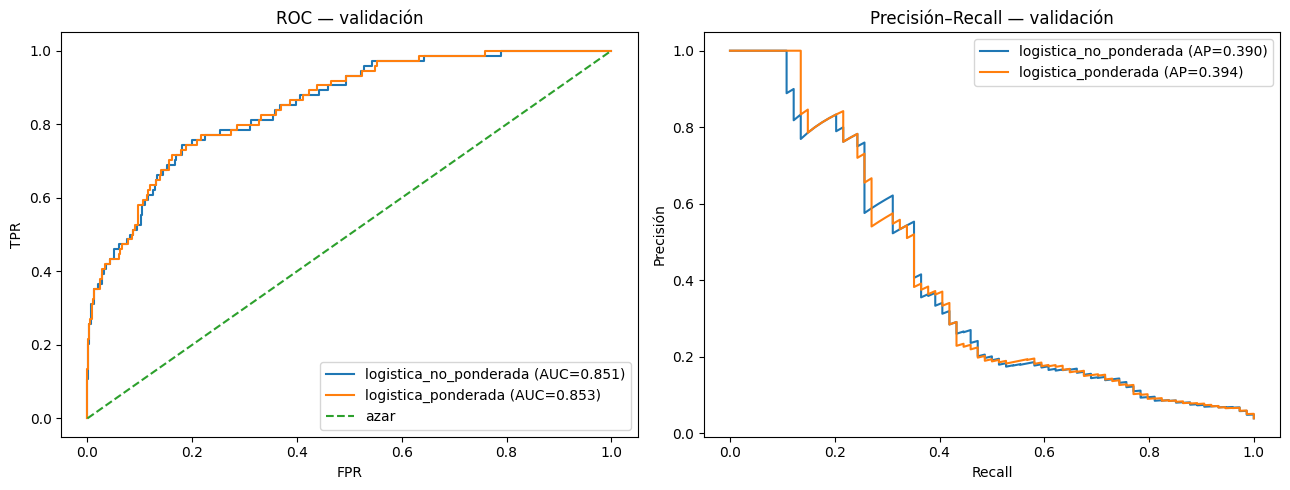

In [ ]:
# Curvas ROC y precisión-recall de validación para los dos candidatos
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nombre, p in p_val.items():
    fpr,tpr,_=roc_curve(val.Y,p)
    prec,rec,_=precision_recall_curve(val.Y,p)
    ax[0].plot(fpr,tpr,label=f"{nombre} (AUC={roc_auc_score(val.Y,p):.3f})")
    ax[1].plot(rec,prec,label=f"{nombre} (AP={average_precision_score(val.Y,p):.3f})")
ax[0].plot([0,1],[0,1],"--",label="azar")
ax[0].set(xlabel="FPR",ylabel="TPR",title="ROC — validación"); ax[0].legend()
ax[1].set(xlabel="Recall",ylabel="Precisión",title="Precisión–Recall — validación"); ax[1].legend()
plt.tight_layout()


Calibración: logistica_no_ponderada


,grupo,n,positivos,probabilidad_media,fraccion_positiva,p_min,p_max
0,1,380,0,0.005385,0.000000,0.000844,0.008059
1,2,379,2,0.010504,0.005277,0.008068,0.013162
2,3,379,9,0.017201,0.023747,0.013194,0.022123
3,4,379,10,0.029710,0.026385,0.022146,0.040757
4,5,379,53,0.090604,0.139842,0.040828,0.806915



Calibración: logistica_ponderada


,grupo,n,positivos,probabilidad_media,fraccion_positiva,p_min,p_max
0,1,380,0,0.150014,0.000000,0.028066,0.209053
1,2,379,2,0.258145,0.005277,0.209617,0.304445
2,3,379,9,0.360116,0.023747,0.305313,0.419991
3,4,379,9,0.489880,0.023747,0.420192,0.570205
4,5,379,54,0.700362,0.142480,0.571455,0.988954


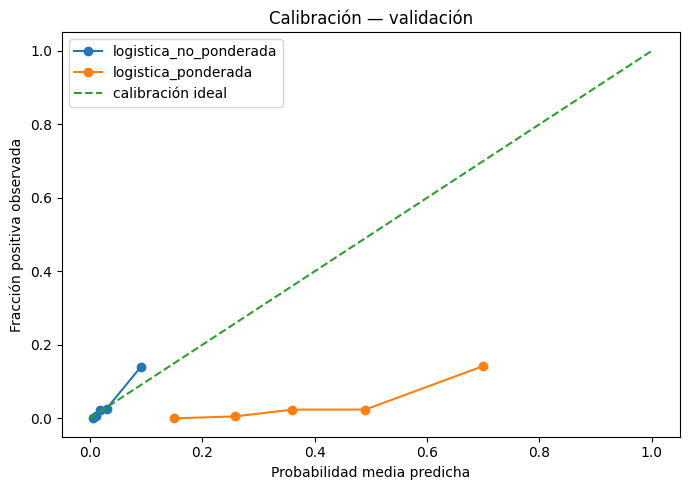

In [ ]:
# Curva de calibración: cinco grupos por cuantiles, con conteo y positivos por grupo.
def tabla_calibracion(y, p, q=5):
    tmp=pd.DataFrame({"y":np.asarray(y,dtype=int),"p":np.asarray(p,dtype=float)})
    # rank(method='first') permite formar grupos incluso con probabilidades repetidas;
    # se informa que los grupos son aproximados por cuantiles de rangos.
    tmp["grupo"]=pd.qcut(tmp.p.rank(method="first"), q=q, labels=False, duplicates="drop")+1
    return tmp.groupby("grupo", observed=True).agg(
        n=("y","size"), positivos=("y","sum"),
        probabilidad_media=("p","mean"), fraccion_positiva=("y","mean"),
        p_min=("p","min"), p_max=("p","max")
    ).reset_index()

tablas_cal = {}
fig, ax = plt.subplots(figsize=(7,5))
for nombre,p in p_val.items():
    tab=tabla_calibracion(val.Y,p,5)
    tablas_cal[nombre]=tab
    ax.plot(tab.probabilidad_media,tab.fraccion_positiva,marker="o",label=nombre)
    print("\nCalibración:",nombre)
    display(tab)
ax.plot([0,1],[0,1],"--",label="calibración ideal")
ax.set(xlabel="Probabilidad media predicha",ylabel="Fracción positiva observada",title="Calibración — validación")
ax.legend(); plt.tight_layout()

### Referencias solicitadas: prevalencia constante y no emitir alertas

In [ ]:
p_constante = np.full(len(val), train.Y.mean(), dtype=float)
referencias_val = {
    "probabilidad_constante_prevalencia_train": metricas_prob(val.Y, p_constante),
    "no_emitir_alertas": metricas_decision(val.Y, np.zeros(len(val), dtype=int))
}
display(pd.DataFrame(referencias_val).T)

,AP,ROC_AUC,log_loss,Brier,TP,TN,FP,FN,precision,recall,especificidad,F1,accuracy,tasa_alertas,alertas_por_1000,costo
probabilidad_constante_prevalencia_train,0.03903,0.5,0.168657,0.03772,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no_emitir_alertas,NaN,NaN,NaN,NaN,0.0,1822.0,0.0,74.0,0.0,0.0,1.0,0.0,0.96097,0.0,0.0,0.468354


## 7. Política de alertas sobre validación (7d)

El costo operativo es `(12·FN + FP)/N`. Las restricciones son `recall ≥ 0.80` y tasa de alertas `≤ 0.15`. Se evalúan todos los umbrales únicos, además de las políticas extremas “alertar todos” y “no alertar ninguno”. Se conserva un campo `modo` para identificarlas explícitamente.

In [ ]:
TAU_TEORICO = 1/(1+12)  # costo FP=1, FN=12, bajo probabilidades verdaderas
def tabla_umbral(y, p):
    y=np.asarray(y,dtype=int); p=np.asarray(p,dtype=float)
    politicas=[]
    # Política extrema no alertar ninguno: threshold mayor que cualquier p, sin redondeo.
    candidatos=[("no_alertar_ninguno", np.nextafter(np.max(p), np.inf), np.zeros(len(p),dtype=int))]
    candidatos.append(("alertar_todos", np.nextafter(np.min(p), -np.inf), np.ones(len(p),dtype=int)))
    # Todo valor único predicho genera una política p >= tau
    for tau in np.unique(p):
        candidatos.append(("umbral", float(tau), (p>=tau).astype(int)))
    for modo,tau,a in candidatos:
        m=metricas_decision(y,a)
        politicas.append({"modo":modo,"tau":float(tau),**m})
    out=pd.DataFrame(politicas).drop_duplicates(["modo","tau"])
    return out.sort_values(["costo","tasa_alertas","tau"],ascending=[True,True,False]).reset_index(drop=True)

p_ganador_val = p_val[ganador_nombre]
tabla_tau = tabla_umbral(val.Y.to_numpy(),p_ganador_val)
factibles = tabla_tau[(tabla_tau.recall >= 0.80) & (tabla_tau.tasa_alertas <= 0.15)].copy()
if len(factibles):
    factibles = factibles.sort_values(["costo","tasa_alertas","tau"],ascending=[True,True,False])
    politica_seleccionada = factibles.iloc[0].to_dict()
    estado_factibilidad = "factible"
else:
    politica_seleccionada = tabla_tau.sort_values(["costo","tasa_alertas","tau"],ascending=[True,True,False]).iloc[0].to_dict()
    estado_factibilidad = "inviabilidad_empirica"

# Diagnósticos solicitados incluso si no hay política factible
hasta15 = tabla_tau[tabla_tau.tasa_alertas <= 0.15]
max_recall_hasta15 = hasta15.recall.max() if len(hasta15) else np.nan
alcanza80 = tabla_tau[tabla_tau.recall >= 0.80]
min_alertas_recall80 = alcanza80.tasa_alertas.min() if len(alcanza80) else np.nan
diagnostica_sin_restricciones = tabla_tau.sort_values(["costo","tasa_alertas","tau"],ascending=[True,True,False]).iloc[0].to_dict()

print("Estado de factibilidad:", estado_factibilidad)
print("Máximo recall con tasa de alertas <= 15 %:", max_recall_hasta15)
print("Menor tasa de alertas que alcanza recall >= 80 %:", min_alertas_recall80)
display(tabla_tau.head(15))
display(pd.DataFrame([politica_seleccionada],index=["política seleccionada o diagnóstico"]).T)

Estado de factibilidad: inviabilidad_empirica
Máximo recall con tasa de alertas <= 15 %: 0.6351351351351351
Menor tasa de alertas que alcanza recall >= 80 %: 0.34651898734177217


,modo,tau,TP,TN,FP,FN,precision,recall,especificidad,F1,accuracy,tasa_alertas,alertas_por_1000,costo
0,umbral,0.635220,47,1603,219,27,0.176692,0.635135,0.879802,0.276471,0.870253,0.140295,140.295359,0.286392
1,umbral,0.634933,47,1602,220,27,0.176030,0.635135,0.879254,0.275660,0.869726,0.140823,140.822785,0.286920
2,umbral,0.613433,50,1566,256,24,0.163399,0.675676,0.859495,0.263158,0.852321,0.161392,161.392405,0.286920
3,umbral,0.634343,47,1601,221,27,0.175373,0.635135,0.878705,0.274854,0.869198,0.141350,141.350211,0.287447
4,umbral,0.613307,50,1565,257,24,0.162866,0.675676,0.858946,0.262467,0.851793,0.161920,161.919831,0.287447
5,umbral,0.591729,53,1529,293,21,0.153179,0.716216,0.839188,0.252381,0.834388,0.182489,182.489451,0.287447
6,umbral,0.632762,47,1600,222,27,0.174721,0.635135,0.878156,0.274052,0.868671,0.141878,141.877637,0.287975
7,umbral,0.613020,50,1564,258,24,0.162338,0.675676,0.858397,0.261780,0.851266,0.162447,162.447257,0.287975
8,umbral,0.590310,53,1528,294,21,0.152738,0.716216,0.838639,0.251781,0.833861,0.183017,183.016878,0.287975
9,umbral,0.632187,47,1599,223,27,0.174074,0.635135,0.877607,0.273256,0.868143,0.142405,142.405063,0.288502


,política seleccionada o diagnóstico
modo,umbral
tau,0.63522
TP,47
TN,1603
FP,219
FN,27
precision,0.176692
recall,0.635135
especificidad,0.879802
F1,0.276471


In [ ]:
# Comparación en validación: tau=0.5, teórico y seleccionado/diagnóstico.
def evaluar_tau_fijo(y,p,tau,modo="umbral"):
    alerta=(np.asarray(p)>=tau).astype(int)
    return {"modo":modo,"tau":float(tau),**metricas_decision(y,alerta),**metricas_prob(y,p)}

politicas_val = [
    evaluar_tau_fijo(val.Y,p_ganador_val,0.5,"tau_0.5"),
    evaluar_tau_fijo(val.Y,p_ganador_val,TAU_TEORICO,"tau_teorico"),
    {**politica_seleccionada, **metricas_prob(val.Y,p_ganador_val)}
]
display(pd.DataFrame(politicas_val))

,modo,tau,TP,TN,FP,FN,precision,recall,especificidad,F1,accuracy,tasa_alertas,alertas_por_1000,costo,AP,ROC_AUC,log_loss,Brier
0,tau_0.5,0.500000,57,1347,475,17,0.107143,0.770270,0.739297,0.188119,0.740506,0.280591,280.590717,0.358122,0.393923,0.85282,0.535092,0.178442
1,tau_teorico,0.076923,74,28,1794,0,0.039615,1.000000,0.015368,0.076210,0.053797,0.985232,985.232068,0.946203,0.393923,0.85282,0.535092,0.178442
2,umbral,0.635220,47,1603,219,27,0.176692,0.635135,0.879802,0.276471,0.870253,0.140295,140.295359,0.286392,0.393923,0.85282,0.535092,0.178442


## 8. Congelar manifiesto antes de abrir prueba (7e, primera parte)

No se reentrena sobre entrenamiento + validación. Se congelan la familia ganadora por CV, su `λ₂`, las variables, la regla de decisión y el umbral seleccionado; si hubo inviabilidad, se congela la política diagnóstica de menor costo sin restricciones y se identifica como tal.

In [ ]:
manifiesto = {
    "seed": SEED,
    "n_total": len(datos),
    "features": FEATURES,
    "fecha_prediccion": "solo ordenar y partir; excluida de X",
    "min_retraso": "solo construir Y; excluida de X",
    "preprocesamiento": {
        "numericas": "imputación por mediana y StandardScaler ajustados dentro de cada entrenamiento",
        "categoricas": "imputación por moda y OneHotEncoder(handle_unknown='ignore')"
    },
    "cortes": {"train": "0 a 60%-24", "gap1": 24, "validation": "60% a 80%-24", "gap2": 24, "test": "80% a final"},
    "modelo_ganador_cv": ganador_nombre,
    "lambda2_ganador_cv": ganador_lambda,
    "lambda_por_familia": selecciones,
    "regla": "alerta = 1 si p >= tau",
    "estado_factibilidad_validacion": estado_factibilidad,
    "politica": politica_seleccionada,
    "politica_diagnostica_sin_restricciones": diagnostica_sin_restricciones,
    "tau_teorico": TAU_TEORICO,
    "test_abierto": False
}
with open("manifiesto_politica.json","w",encoding="utf-8") as f:
    json.dump(manifiesto,f,ensure_ascii=False,indent=2,default=float)
print(json.dumps(manifiesto,ensure_ascii=False,indent=2,default=float))

{
  "seed": 2026,
  "n_total": 9600,
  "features": [
    "hora_salida",
    "distancia_km",
    "lluvia_pronosticada_mm",
    "viento_pronosticado_kmh",
    "ocupacion_programada_pct",
    "trafico_programado",
    "aerolinea",
    "origen"
  ],
  "fecha_prediccion": "solo ordenar y partir; excluida de X",
  "min_retraso": "solo construir Y; excluida de X",
  "preprocesamiento": {
    "numericas": "imputación por mediana y StandardScaler ajustados dentro de cada entrenamiento",
    "categoricas": "imputación por moda y OneHotEncoder(handle_unknown='ignore')"
  },
  "cortes": {
    "train": "0 a 60%-24",
    "gap1": 24,
    "validation": "60% a 80%-24",
    "gap2": 24,
    "test": "80% a final"
  },
  "modelo_ganador_cv": "logistica_ponderada",
  "lambda2_ganador_cv": 0.1,
  "lambda_por_familia": {
    "logistica_no_ponderada": 0.01,
    "logistica_ponderada": 0.1
  },
  "regla": "alerta = 1 si p >= tau",
  "estado_factibilidad_validacion": "inviabilidad_empirica",
  "politica": {
    "

## 9. Evaluación final única sobre prueba (7e)

**Esta sección debe ejecutarse una sola vez, después de guardar el manifiesto.** Se utiliza el modelo ya ajustado exclusivamente con entrenamiento y las tres políticas congeladas. No se cambia el umbral tras observar la prueba.

In [ ]:
# Confirmación explícita de que el manifiesto existe y está congelado antes de evaluar prueba.
assert Path("manifiesto_politica.json").exists()
with open("manifiesto_politica.json",encoding="utf-8") as f:
    manifiesto_leido=json.load(f)
assert manifiesto_leido["test_abierto"] is False

# El candidato congelado es el ganador de CV ya ajustado solo en train.
p_test = obtener_p(candidatos[ganador_nombre], test, ganador_nombre=="logistica_ponderada")
tau_sel = float(politica_seleccionada["tau"])
politicas_finales = [
    ("tau_0.5", 0.5),
    ("tau_teorico", TAU_TEORICO),
    ("politica_seleccionada_o_diagnostica", tau_sel)
]

In [ ]:
# Métricas de decisión con NumPy; comparación de la matriz de confusión con sklearn.
def reporte_final(y,p,tau,nombre):
    alerta=(np.asarray(p)>=tau).astype(int)
    TP,TN,FP,FN=confusiones_numpy(y,alerta)
    cm=confusion_matrix(y,alerta,labels=[0,1])
    assert (TN,FP,FN,TP)==(int(cm[0,0]),int(cm[0,1]),int(cm[1,0]),int(cm[1,1]))
    m=metricas_decision(y,alerta)
    m.update(metricas_prob(y,p))
    m.update({"politica":nombre,"tau":tau,"TN_sklearn":int(cm[0,0]),"FP_sklearn":int(cm[0,1]),
              "FN_sklearn":int(cm[1,0]),"TP_sklearn":int(cm[1,1])})
    return m, cm, alerta

reportes=[]; matrices={}; alertas={}
for nombre,tau in politicas_finales:
    m,cm,a=reporte_final(test.Y.to_numpy(),p_test,tau,nombre)
    reportes.append(m); matrices[nombre]=cm; alertas[nombre]=a
display(pd.DataFrame(reportes).set_index("politica"))
for nombre,cm in matrices.items():
    print(nombre, "\nfilas=Y real [0,1], columnas=predicción [0,1]")
    display(pd.DataFrame(cm,index=["Y=0","Y=1"],columns=["pred=0","pred=1"]))

,TP,TN,FP,FN,precision,recall,especificidad,F1,accuracy,tasa_alertas,alertas_por_1000,costo,AP,ROC_AUC,log_loss,Brier,tau,TN_sklearn,FP_sklearn,FN_sklearn,TP_sklearn
politica,,,,,,,,,,,,,,,,,,,,,
tau_0.5,57,1284,565,14,0.091640,0.802817,0.694429,0.164502,0.698438,0.323958,323.958333,0.381771,0.409139,0.868821,0.561054,0.19075,0.500000,1284,565,14,57
tau_teorico,71,28,1821,0,0.037526,1.000000,0.015143,0.072338,0.051562,0.985417,985.416667,0.948438,0.409139,0.868821,0.561054,0.19075,0.076923,28,1821,0,71
politica_seleccionada_o_diagnostica,50,1615,234,21,0.176056,0.704225,0.873445,0.281690,0.867188,0.147917,147.916667,0.253125,0.409139,0.868821,0.561054,0.19075,0.635220,1615,234,21,50


tau_0.5 
filas=Y real [0,1], columnas=predicción [0,1]


,pred=0,pred=1
Y=0,1284,565
Y=1,14,57


tau_teorico 
filas=Y real [0,1], columnas=predicción [0,1]


,pred=0,pred=1
Y=0,28,1821
Y=1,0,71


politica_seleccionada_o_diagnostica 
filas=Y real [0,1], columnas=predicción [0,1]


,pred=0,pred=1
Y=0,1615,234
Y=1,21,50


In [ ]:
# Las métricas basadas exclusivamente en probabilidades deben ser idénticas para los tres umbrales.
metricas_prob_test = [metricas_prob(test.Y,p_test) for _ in politicas_finales]
assert all(m == metricas_prob_test[0] for m in metricas_prob_test[1:])
print("Verificación correcta: AP, ROC-AUC, log-loss y Brier son invariantes al umbral.")

# Restricciones operativas de cada política en prueba
tabla_final = pd.DataFrame(reportes).set_index("politica")
tabla_final["cumple_recall_0.80"] = tabla_final["recall"] >= 0.80
tabla_final["cumple_alertas_0.15"] = tabla_final["tasa_alertas"] <= 0.15
tabla_final["cumple_ambas"] = tabla_final["cumple_recall_0.80"] & tabla_final["cumple_alertas_0.15"]
display(tabla_final[["recall","tasa_alertas","costo","cumple_recall_0.80","cumple_alertas_0.15","cumple_ambas"]])

Verificación correcta: AP, ROC-AUC, log-loss y Brier son invariantes al umbral.


,recall,tasa_alertas,costo,cumple_recall_0.80,cumple_alertas_0.15,cumple_ambas
politica,,,,,,
tau_0.5,0.802817,0.323958,0.381771,True,False,False
tau_teorico,1.000000,0.985417,0.948438,True,False,False
politica_seleccionada_o_diagnostica,0.704225,0.147917,0.253125,False,True,False


In [ ]:
# Exportar predicciones finales con ID, fecha, objetivo, probabilidad y decisión para cada política.
pred_final = test[["id_fila","fecha_prediccion","Y"]].copy()
pred_final["p_retraso_ge_15"] = p_test
for nombre,tau in politicas_finales:
    pred_final["alerta_"+nombre] = (p_test >= tau).astype(int)
pred_final.to_csv("predicciones_prueba_problema7.csv",index=False)
display(pred_final.head())

,id_fila,fecha_prediccion,Y,p_retraso_ge_15,alerta_tau_0.5,alerta_tau_teorico,alerta_politica_seleccionada_o_diagnostica
7680,7680,2024-11-16 00:00:00,0,0.158005,0,1,0
7681,7681,2024-11-16 01:00:00,0,0.737736,1,1,1
7682,7682,2024-11-16 02:00:00,0,0.280185,0,1,0
7683,7683,2024-11-16 03:00:00,1,0.832905,1,1,1
7684,7684,2024-11-16 04:00:00,0,0.393819,0,1,0


## 10. Conclusiones que deben completarse después de ejecutar

1. **Temporalidad y fuga:** documenta los rangos de fechas/IDs y confirma que los gaps tienen 24 filas y que no hay solapamientos.
2. **Selección:** informa AP media y dispersión de los cuatro pliegues; explica el desempate aplicado.
3. **Contraexperimento:** compara AP y log-loss del preprocesamiento correcto y contaminado. La diferencia numérica no es, por sí sola, la definición de fuga.
4. **Calibración:** interpreta los cinco grupos, indicando tamaños y positivos; diferencia AP de la aproximación trapezoidal del área bajo PR.
5. **Política:** reporta factibilidad o inviabilidad empírica. Compara el umbral de costo teórico `1/13 ≈ 0.0769` —que supone probabilidades verdaderas— con `0.5` y con la política congelada.
6. **Prueba:** presenta métricas y restricciones una sola vez. Cumplir en validación no garantiza cumplir en prueba porque las observaciones y la prevalencia pueden variar.
7. **Limitaciones:** las fechas sintéticas, el mecanismo del generador y la elección de variables limitan la generalización a operaciones reales.